<a href="https://colab.research.google.com/github/srigstinahf/Proyek_SpesialSkill03/blob/main/ProjectCamp03_SpecialSkill_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Camp 03 — Model Deep Learning CNN untuk Deteksi Gambar

## Deskripsi Proyek
Notebook ini membangun model **Convolutional Neural Network (CNN)** untuk **klasifikasi gambar** menggunakan dataset CIFAR-10.

Dataset CIFAR-10 terdiri dari **60.000 gambar berwarna** berukuran 32×32 pixel dalam **10 kelas**:
`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`

---

## Alur Notebook
1. Import Library
2. Load & Eksplorasi Dataset
3. Preprocessing Data
4. Bangun Arsitektur Model CNN
5. Kompilasi & Training Model
6. Evaluasi Model
7. Visualisasi Hasil
8. Prediksi Gambar Baru

---
## Bagian 1: Import Library
Library adalah kumpulan kode yang sudah dibuat orang lain agar kita tidak perlu menulis dari nol.

In [ ]:
# ── Import Library Utama ────────────────────────────────────────────────────

import numpy as np                        # Library komputasi numerik (array, matriks)
import matplotlib.pyplot as plt           # Library untuk membuat grafik dan visualisasi
import matplotlib.patches as mpatches    # Untuk membuat legenda pada grafik
import seaborn as sns                     # Library visualisasi statistik (heatmap confusion matrix)

# ── TensorFlow & Keras ─────────────────────────────────────────────────────
# TensorFlow adalah framework deep learning buatan Google.
# Keras adalah antarmuka (API) tingkat tinggi di atas TensorFlow agar lebih mudah digunakan.

import tensorflow as tf                   # Framework utama deep learning

from tensorflow.keras import layers, models   # 'layers' = lapisan-lapisan CNN, 'models' = wadah modelnya
from tensorflow.keras.datasets import cifar10 # Dataset CIFAR-10 sudah tersedia langsung di Keras
from tensorflow.keras.utils import to_categorical  # Untuk mengubah label angka menjadi format one-hot
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau  # Callback untuk kontrol training
from tensorflow.keras.preprocessing.image import ImageDataGenerator     # Augmentasi data gambar

from sklearn.metrics import classification_report, confusion_matrix  # Evaluasi performa model

# ── Konfigurasi Tampilan ───────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-darkgrid')   # Tema grafik agar tampil lebih rapi
np.random.seed(42)                        # Seed random agar hasil eksperimen bisa direproduksi
tf.random.set_seed(42)                    # Seed random untuk TensorFlow

# ── Cek Versi & GPU ───────────────────────────────────────────────────────
print(f'TensorFlow versi: {tf.__version__}')    # Tampilkan versi TensorFlow yang terinstall
print(f'GPU tersedia: {tf.config.list_physical_devices("GPU")}')  # Cek apakah GPU aktif di Colab

TensorFlow versi: 2.20.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Bagian 2: Load & Eksplorasi Dataset
Saya menggunakan **CIFAR-10**, dataset benchmark populer di dunia Computer Vision.

In [ ]:
# ── Load Dataset CIFAR-10 ──────────────────────────────────────────────────
# Keras otomatis mengunduh CIFAR-10 jika belum ada di cache lokal.
# Dataset sudah dibagi menjadi data TRAIN (latih) dan TEST (uji).

(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# X_train = gambar untuk training  | y_train = label kelas untuk training
# X_test  = gambar untuk testing   | y_test  = label kelas untuk testing

# ── Nama Kelas ─────────────────────────────────────────────────────────────
# CIFAR-10 memiliki 10 kelas objek. Indeks 0–9 mewakili nama di bawah ini:
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# ── Info Dimensi Data ──────────────────────────────────────────────────────
print('=== INFO DATASET ===')
print(f'Jumlah data training  : {X_train.shape[0]} gambar')   # 50.000 gambar
print(f'Jumlah data testing   : {X_test.shape[0]} gambar')    # 10.000 gambar
print(f'Dimensi tiap gambar   : {X_train.shape[1:]}')         # (32, 32, 3) = tinggi x lebar x channel RGB
print(f'Jumlah kelas          : {len(CLASS_NAMES)}')
print(f'Nilai piksel minimum  : {X_train.min()}')
print(f'Nilai piksel maksimum : {X_train.max()}')

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 91s 1us/step
=== INFO DATASET ===
Jumlah data training  : 50000 gambar
Jumlah data testing   : 10000 gambar
Dimensi tiap gambar   : (32, 32, 3)
Jumlah kelas          : 10
Nilai piksel minimum  : 0
Nilai piksel maksimum : 255


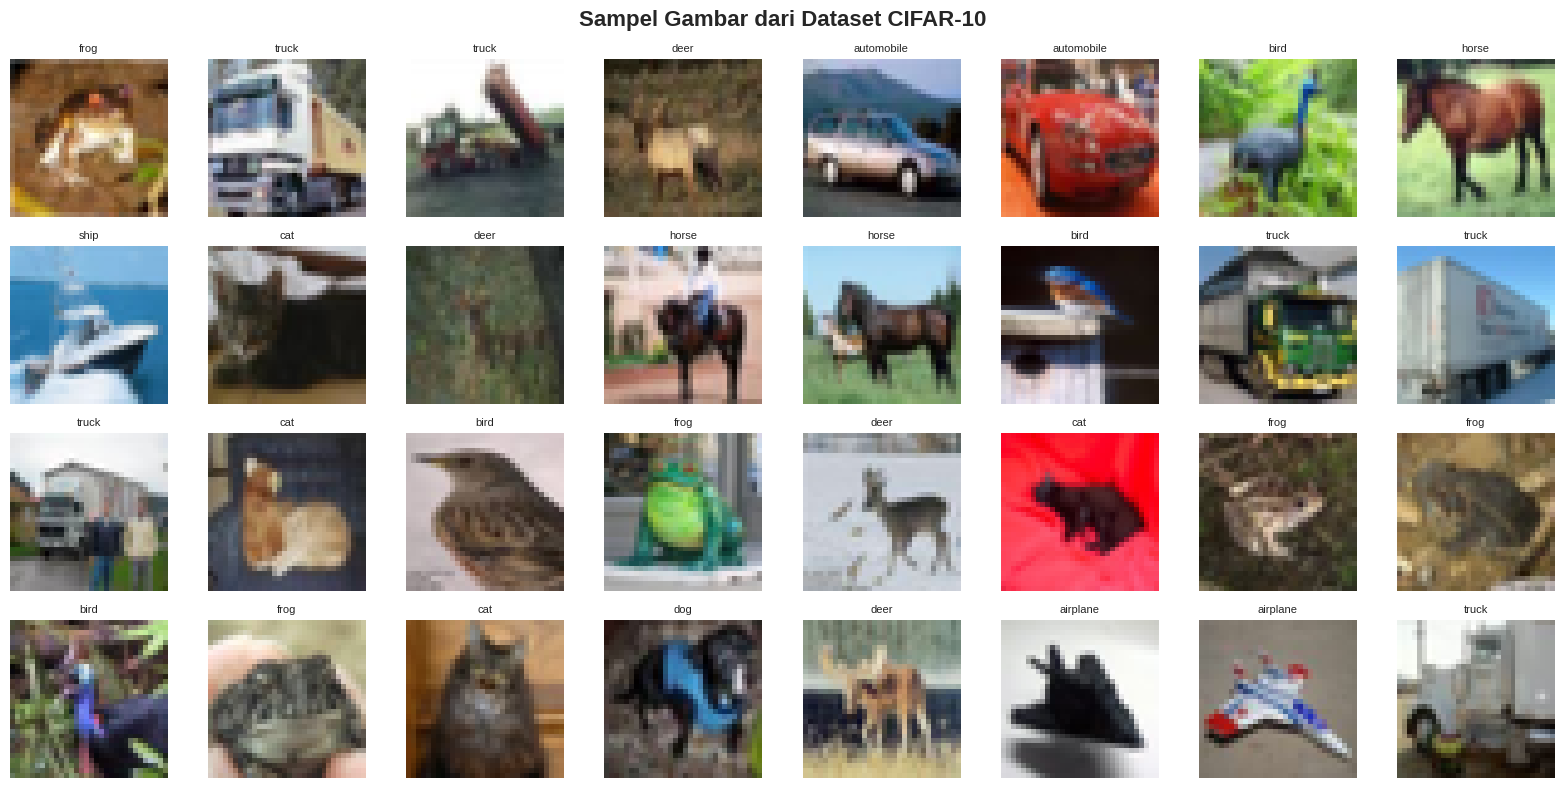

In [ ]:
# ── Visualisasi Sampel Gambar dari Dataset ─────────────────────────────────
# Sebelum melatih model, penting untuk MELIHAT datanya terlebih dahulu
# agar kita memahami apa yang sedang kita kerjakan.

fig, axes = plt.subplots(4, 8, figsize=(16, 8))  # Buat grid 4 baris x 8 kolom = 32 gambar
fig.suptitle('Sampel Gambar dari Dataset CIFAR-10', fontsize=16, fontweight='bold')  # Judul utama

axes = axes.ravel()   # Ubah array 2D axes menjadi 1D agar mudah diiterasi

for i in range(32):   # Loop untuk menampilkan 32 gambar pertama
    axes[i].imshow(X_train[i])                    # Tampilkan gambar ke-i
    axes[i].set_title(CLASS_NAMES[y_train[i][0]], # Judul = nama kelas gambar
                      fontsize=8)
    axes[i].axis('off')                           # Sembunyikan sumbu x/y agar bersih

plt.tight_layout()    # Atur jarak antar subplot otomatis agar tidak tumpang tindih
plt.show()            # Tampilkan gambar

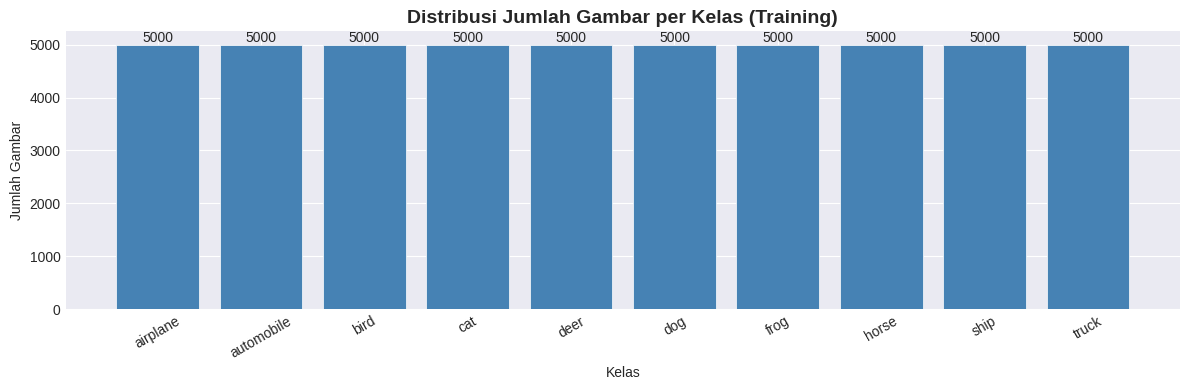

✅ Dataset seimbang — setiap kelas memiliki jumlah gambar yang sama.


In [ ]:
# ── Distribusi Kelas ───────────────────────────────────────────────────────
# Cek apakah jumlah data tiap kelas seimbang (balanced) atau tidak (imbalanced).
# Data yang tidak seimbang dapat menyebabkan model bias ke kelas tertentu.

unique, counts = np.unique(y_train, return_counts=True)  # Hitung frekuensi tiap label

plt.figure(figsize=(12, 4))                              # Ukuran canvas grafik
plt.bar([CLASS_NAMES[i] for i in unique], counts,        # Buat bar chart
        color='steelblue', edgecolor='white', linewidth=0.5)
plt.title('Distribusi Jumlah Gambar per Kelas (Training)', fontsize=14, fontweight='bold')
plt.xlabel('Kelas')                # Label sumbu x
plt.ylabel('Jumlah Gambar')        # Label sumbu y
plt.xticks(rotation=30)            # Putar label sumbu x agar tidak tumpang tindih
for i, v in enumerate(counts):    # Tambahkan angka di atas tiap batang
    plt.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()
print('✅ Dataset seimbang — setiap kelas memiliki jumlah gambar yang sama.')

---
## Bagian 3: Preprocessing Data
Preprocessing adalah tahap mempersiapkan data mentah agar siap digunakan untuk melatih model.

In [ ]:
# ── Normalisasi Nilai Piksel ───────────────────────────────────────────────
# Nilai piksel asli berada di rentang 0–255 (integer).
# Neural network bekerja lebih baik dengan nilai kecil (0.0–1.0).
# Cara normalisasi: bagi semua nilai dengan 255.0

X_train = X_train.astype('float32') / 255.0   # Ubah tipe data ke float lalu bagi 255
X_test  = X_test.astype('float32')  / 255.0   # Lakukan hal yang sama untuk data test

print(f'Nilai piksel setelah normalisasi — min: {X_train.min():.1f}, max: {X_train.max():.1f}')

# ── One-Hot Encoding Label ─────────────────────────────────────────────────
# Label asli berupa angka tunggal, misal: 3 (artinya 'cat').
# Kita ubah ke format vektor biner (one-hot), misal: [0,0,0,1,0,0,0,0,0,0]
# Ini diperlukan agar sesuai dengan output layer model yang memiliki 10 neuron.

NUM_CLASSES = 10                                        # Jumlah kelas
y_train_cat = to_categorical(y_train, NUM_CLASSES)      # Encode label training
y_test_cat  = to_categorical(y_test,  NUM_CLASSES)      # Encode label testing

print(f'\nContoh label asli  : {y_train[0][0]}  → kelas "{CLASS_NAMES[y_train[0][0]]}')
print(f'Setelah one-hot     : {y_train_cat[0]}')

# ── Pisah Validation Set ──────────────────────────────────────────────────
# Validation set digunakan untuk memantau performa model SELAMA training
# tanpa 'mengintip' data test. Kita ambil 10% dari training data.

VAL_SIZE = 5000                                # Jumlah sampel untuk validasi
X_val   = X_train[:VAL_SIZE]                   # Ambil 5000 gambar pertama sebagai validation
y_val   = y_train_cat[:VAL_SIZE]               # Label validasinya
X_train_final = X_train[VAL_SIZE:]             # Sisa 45000 gambar untuk training
y_train_final = y_train_cat[VAL_SIZE:]         # Label training yang tersisa

print(f'\nUkuran data training : {X_train_final.shape[0]} gambar')
print(f'Ukuran data validasi : {X_val.shape[0]} gambar')
print(f'Ukuran data testing  : {X_test.shape[0]} gambar')

Nilai piksel setelah normalisasi — min: 0.0, max: 1.0

Contoh label asli  : 6  → kelas "frog
Setelah one-hot     : [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

Ukuran data training : 45000 gambar
Ukuran data validasi : 5000 gambar
Ukuran data testing  : 10000 gambar


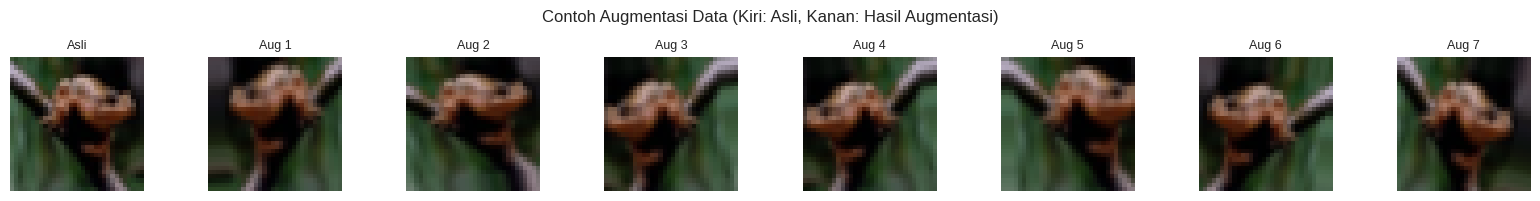

In [ ]:
# ── Augmentasi Data (Data Augmentation) ───────────────────────────────────
# Augmentasi adalah teknik memperbanyak variasi data training secara buatan
# dengan cara memodifikasi gambar (flip, rotasi, zoom, geser, dll.).
# Tujuannya: mencegah OVERFITTING (model terlalu hafal data training).

datagen = ImageDataGenerator(
    rotation_range=15,        # Putar gambar secara acak maksimal 15 derajat
    width_shift_range=0.1,    # Geser horizontal maksimal 10% dari lebar gambar
    height_shift_range=0.1,   # Geser vertikal maksimal 10% dari tinggi gambar
    horizontal_flip=True,     # Cerminkan gambar secara horizontal (flip kiri-kanan)
    zoom_range=0.1,           # Zoom in/out gambar secara acak hingga 10%
    fill_mode='nearest'       # Isi piksel kosong akibat pergeseran dengan nilai tetangga terdekat
)

datagen.fit(X_train_final)    # Hitung statistik augmentasi berdasarkan data training

# ── Visualisasi Efek Augmentasi ───────────────────────────────────────────
# Tampilkan 1 gambar asli vs 7 versi augmentasinya
sample_img = X_train_final[0:1]           # Ambil 1 gambar (shape: 1, 32, 32, 3)
sample_gen = datagen.flow(sample_img, batch_size=1)  # Generator augmentasi untuk gambar ini

fig, axes = plt.subplots(1, 8, figsize=(16, 2))
fig.suptitle('Contoh Augmentasi Data (Kiri: Asli, Kanan: Hasil Augmentasi)', fontsize=12)
axes[0].imshow(sample_img[0])             # Gambar asli
axes[0].set_title('Asli', fontsize=9)
axes[0].axis('off')
for i in range(1, 8):                     # 7 versi augmentasi
    aug_img = next(sample_gen)[0]         # Ambil 1 batch dari generator
    axes[i].imshow(aug_img.clip(0, 1))    # Clip agar nilai tetap 0–1
    axes[i].set_title(f'Aug {i}', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
## Bagian 4: Arsitektur Model CNN

**CNN (Convolutional Neural Network)** adalah arsitektur neural network yang dirancang khusus untuk data gambar. CNN bekerja dengan cara:
1. **Convolutional Layer** → Mendeteksi fitur lokal (tepi, tekstur, pola)
2. **Pooling Layer** → Mereduksi ukuran spasial (ringkas informasi)
3. **Flatten** → Mengubah matriks 2D menjadi vektor 1D
4. **Dense Layer** → Klasifikasi akhir berdasarkan fitur yang diekstrak

In [ ]:
# ── Bangun Arsitektur Model CNN ────────────────────────────────────────────
# Kita menggunakan Sequential API: lapisan ditumpuk satu per satu secara berurutan.

model = models.Sequential(name='CNN_CIFAR10')  # Inisialisasi model Sequential

# ═══════════════════════════════════════════
# BLOK 1 — Deteksi fitur tingkat rendah (tepi, warna)
# ═══════════════════════════════════════════

model.add(layers.Conv2D(
    filters=32,           # 32 filter/kernel yang akan belajar mendeteksi 32 pola berbeda
    kernel_size=(3, 3),   # Ukuran setiap filter: 3x3 piksel
    activation='relu',    # ReLU: aktifkan hanya nilai positif, mencegah masalah vanishing gradient
    padding='same',       # Padding 'same': output memiliki ukuran sama dengan input
    input_shape=(32, 32, 3)  # Input: gambar 32x32 piksel dengan 3 channel warna (RGB)
))
model.add(layers.BatchNormalization())  # Normalisasi output tiap batch → training lebih stabil

model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))  # Layer Conv kedua
model.add(layers.BatchNormalization())  # Normalisasi batch lagi

model.add(layers.MaxPooling2D(pool_size=(2, 2)))  # Pooling: ambil nilai MAX dari area 2x2 → ukuran jadi 16x16
model.add(layers.Dropout(0.25))                   # Dropout 25%: matikan 25% neuron secara acak untuk mencegah overfitting

# ═══════════════════════════════════════════
# BLOK 2 — Deteksi fitur tingkat menengah (bentuk, kontur)
# ═══════════════════════════════════════════

model.add(layers.Conv2D(
    filters=64,           # Jumlah filter ditambah menjadi 64 untuk menangkap pola yang lebih kompleks
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))
model.add(layers.BatchNormalization())

model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

model.add(layers.MaxPooling2D(pool_size=(2, 2)))  # Pooling lagi → ukuran gambar menjadi 8x8
model.add(layers.Dropout(0.30))                   # Dropout 30%

# ═══════════════════════════════════════════
# BLOK 3 — Deteksi fitur tingkat tinggi (bagian objek, struktur global)
# ═══════════════════════════════════════════

model.add(layers.Conv2D(
    filters=128,          # 128 filter untuk fitur yang lebih abstrak dan kompleks
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))
model.add(layers.BatchNormalization())

model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

model.add(layers.MaxPooling2D(pool_size=(2, 2)))  # Pooling → ukuran gambar menjadi 4x4
model.add(layers.Dropout(0.40))                   # Dropout 40%

# ═══════════════════════════════════════════
# HEAD KLASIFIKASI — Membuat keputusan akhir
# ═══════════════════════════════════════════

model.add(layers.Flatten())  # Ratakan tensor 4x4x128 menjadi vektor 1D sepanjang 2048

model.add(layers.Dense(
    units=256,            # 256 neuron fully-connected
    activation='relu'     # Aktivasi ReLU
))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.50))  # Dropout lebih besar di layer Dense untuk regularisasi kuat

model.add(layers.Dense(
    units=NUM_CLASSES,    # Output: 10 neuron (satu per kelas)
    activation='softmax'  # Softmax: ubah output menjadi probabilitas yang berjumlah 1.0
))

# ── Tampilkan Ringkasan Arsitektur ────────────────────────────────────────
model.summary()  # Cetak tabel ringkasan semua lapisan, dimensi output, dan jumlah parameter

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "CNN_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 816,938 (3.12 MB)

 Trainable params: 815,530 (3.11 MB)

 Non-trainable params: 1,408 (5.50 KB)

---
## Bagian 5: Kompilasi & Training Model

In [ ]:
# ── Kompilasi Model ────────────────────────────────────────────────────────
# Sebelum dilatih, model perlu dikonfigurasi dengan 3 hal:
# 1. Optimizer: algoritma untuk mengupdate bobot (weights) model
# 2. Loss function: fungsi yang mengukur seberapa salah prediksi model
# 3. Metrics: cara kita mengukur performa model (akurasi)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    # Adam: optimizer adaptif yang menggabungkan momentum + RMSprop
    # learning_rate=0.001: ukuran langkah saat mengupdate bobot

    loss='categorical_crossentropy',
    # Loss function untuk klasifikasi multi-kelas dengan label one-hot
    # Rumus: -Σ y_true * log(y_pred)

    metrics=['accuracy']
    # Metrik yang ditampilkan selama training: akurasi klasifikasi
)

print('✅ Model berhasil dikompilasi!')

✅ Model berhasil dikompilasi!


In [ ]:
# ── Callback: Kontrol Otomatis Proses Training ────────────────────────────
# Callback adalah fungsi yang dipanggil otomatis di setiap akhir epoch training.

callbacks = [
    EarlyStopping(
        monitor='val_accuracy',  # Pantau akurasi di data validasi
        patience=10,             # Hentikan jika tidak ada peningkatan selama 10 epoch berturut-turut
        restore_best_weights=True,  # Kembalikan bobot model ke epoch terbaik
        verbose=1                # Tampilkan pesan saat early stopping aktif
    ),
    ReduceLROnPlateau(
        monitor='val_loss',     # Pantau loss di data validasi
        factor=0.5,             # Kurangi learning rate menjadi 50% (lr = lr * 0.5)
        patience=5,             # Kurangi lr jika tidak ada perbaikan selama 5 epoch
        min_lr=1e-6,            # Batas minimum learning rate
        verbose=1               # Tampilkan pesan saat lr dikurangi
    )
]

# ── Training Model ────────────────────────────────────────────────────────
# Ini adalah tahap inti: model belajar dari data training selama beberapa epoch.
# Satu EPOCH = model melihat seluruh data training sekali.

BATCH_SIZE = 64   # Jumlah gambar yang diproses sekaligus sebelum bobot diupdate
EPOCHS = 60       # Maksimum jumlah epoch (bisa berhenti lebih awal karena EarlyStopping)

print('⏳ Mulai training model...')
print(f'   Batch size : {BATCH_SIZE}')
print(f'   Max epochs : {EPOCHS}')
print()

history = model.fit(
    datagen.flow(X_train_final, y_train_final, batch_size=BATCH_SIZE),
    # Gunakan generator augmentasi sebagai sumber data training

    steps_per_epoch=len(X_train_final) // BATCH_SIZE,
    # Jumlah batch per epoch = total data / batch_size

    epochs=EPOCHS,                   # Jumlah epoch maksimum
    validation_data=(X_val, y_val),  # Data validasi untuk memantau performa
    callbacks=callbacks,             # Daftar callback yang akan dijalankan
    verbose=1                        # Tampilkan progress bar per epoch
)

⏳ Mulai training model...
   Batch size : 64
   Max epochs : 60

Epoch 1/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 54s 56ms/step - accuracy: 0.3805 - loss: 1.8263 - val_accuracy: 0.4672 - val_loss: 1.5352 - learning_rate: 0.0010
Epoch 2/60
  1/703 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.3906 - loss: 1.7138

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 0s 684us/step - accuracy: 0.3906 - loss: 1.7138 - val_accuracy: 0.4642 - val_loss: 1.5420 - learning_rate: 0.0010
Epoch 3/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.5366 - loss: 1.2897 - val_accuracy: 0.5032 - val_loss: 1.6809 - learning_rate: 0.0010
Epoch 4/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6250 - loss: 0.9557 - val_accuracy: 0.4994 - val_loss: 1.6840 - learning_rate: 0.0010
Epoch 5/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.6083 - loss: 1.1018 - val_accuracy: 0.5546 - val_loss: 1.3677 - learning_rate: 0.0010
Epoch 6/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 883us/step - accuracy: 0.5625 - loss: 1.0527 - val_accuracy: 0.5650 - val_loss: 1.3219 - learning_rate: 0.0010
Epoch 7/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.6483 - loss: 0.9983 - val_accuracy: 0.6058 - val_loss: 1.1855 - learning_rate: 0.0010
Epoch 8/60
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 861us/step - accuracy: 0.6406 - loss: 0.9223 -

---
## Bagian 6: Evaluasi Model

In [ ]:
# ── Evaluasi pada Data Test ────────────────────────────────────────────────
# Evaluasi akhir dilakukan pada data test yang TIDAK PERNAH dilihat model selama training.
# Ini adalah ukuran performa model yang paling objektif.

test_loss, test_acc = model.evaluate(
    X_test, y_test_cat,   # Data test (gambar + label)
    verbose=0             # Tidak perlu tampilkan progress bar
)

print('=' * 50)
print('📊 HASIL EVALUASI MODEL PADA DATA TEST')
print('=' * 50)
print(f'  Loss     : {test_loss:.4f}')        # Loss yang lebih kecil = lebih baik
print(f'  Akurasi  : {test_acc * 100:.2f}%')  # Persentase prediksi yang benar
print('=' * 50)

📊 HASIL EVALUASI MODEL PADA DATA TEST
  Loss     : 0.4315
  Akurasi  : 85.77%


In [ ]:
# ── Classification Report ─────────────────────────────────────────────────
# Classification report memberikan detail performa PER KELAS:
# - Precision: dari semua yang diprediksi kelas X, berapa % yang benar?
# - Recall   : dari semua yang sebenarnya kelas X, berapa % yang terdeteksi?
# - F1-Score : rata-rata harmonik precision & recall (ukuran keseimbangan)

y_pred_proba = model.predict(X_test, verbose=0)    # Prediksi probabilitas untuk setiap kelas
y_pred = np.argmax(y_pred_proba, axis=1)           # Ambil indeks kelas dengan probabilitas tertinggi
y_true = y_test.flatten()                          # Ratakan array label asli menjadi 1D

print('\n📋 CLASSIFICATION REPORT:')
print(classification_report(
    y_true, y_pred,             # Label asli vs label prediksi
    target_names=CLASS_NAMES    # Gunakan nama kelas yang sudah kita definisikan
))


📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    airplane       0.90      0.85      0.88      1000
  automobile       0.92      0.95      0.93      1000
        bird       0.89      0.76      0.82      1000
         cat       0.82      0.67      0.73      1000
        deer       0.84      0.85      0.84      1000
         dog       0.83      0.75      0.79      1000
        frog       0.73      0.97      0.83      1000
       horse       0.88      0.92      0.90      1000
        ship       0.94      0.93      0.93      1000
       truck       0.87      0.94      0.91      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



---
## Bagian 7: Visualisasi Hasil Training

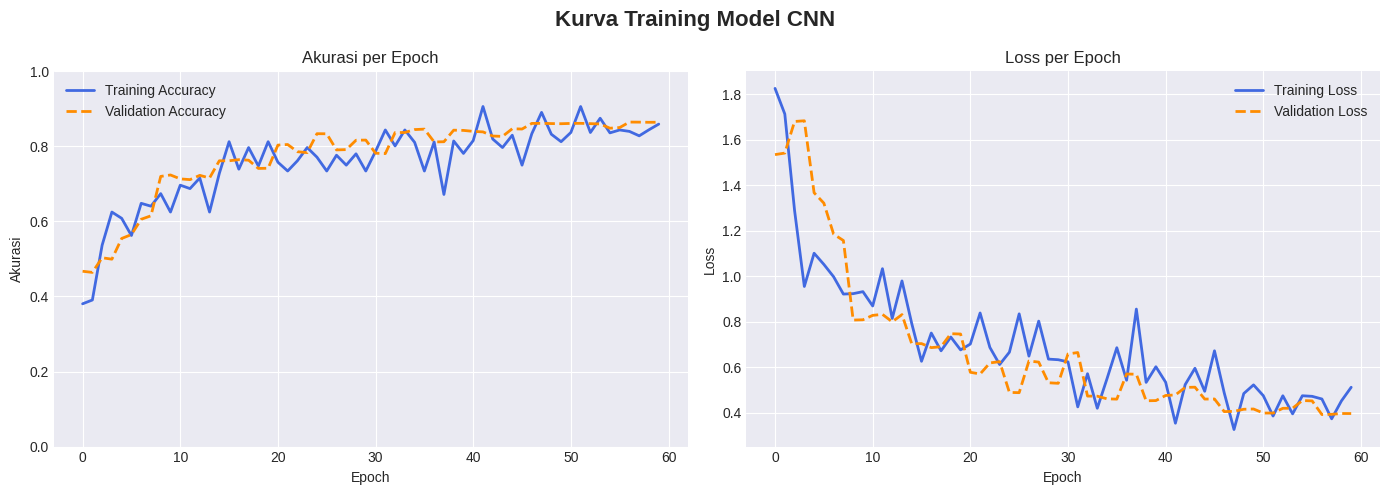

In [ ]:
# ── Plot Kurva Training ────────────────────────────────────────────────────
# Kurva training menunjukkan bagaimana akurasi dan loss berubah setiap epoch.
# Jika training dan validasi berjalan beriringan = model belajar dengan baik.
# Jika training jauh lebih baik dari validasi = OVERFITTING.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))  # 2 subplot: akurasi & loss
fig.suptitle('Kurva Training Model CNN', fontsize=16, fontweight='bold')

# Plot Akurasi
ax1.plot(history.history['accuracy'],     label='Training Accuracy',   color='royalblue',   linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='darkorange',  linewidth=2, linestyle='--')
ax1.set_title('Akurasi per Epoch')    # Judul subplot
ax1.set_xlabel('Epoch')               # Label sumbu x
ax1.set_ylabel('Akurasi')             # Label sumbu y
ax1.legend()                          # Tampilkan legenda
ax1.set_ylim([0, 1])                  # Sumbu y dari 0 sampai 1

# Plot Loss
ax2.plot(history.history['loss'],     label='Training Loss',   color='royalblue',  linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='darkorange', linewidth=2, linestyle='--')
ax2.set_title('Loss per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

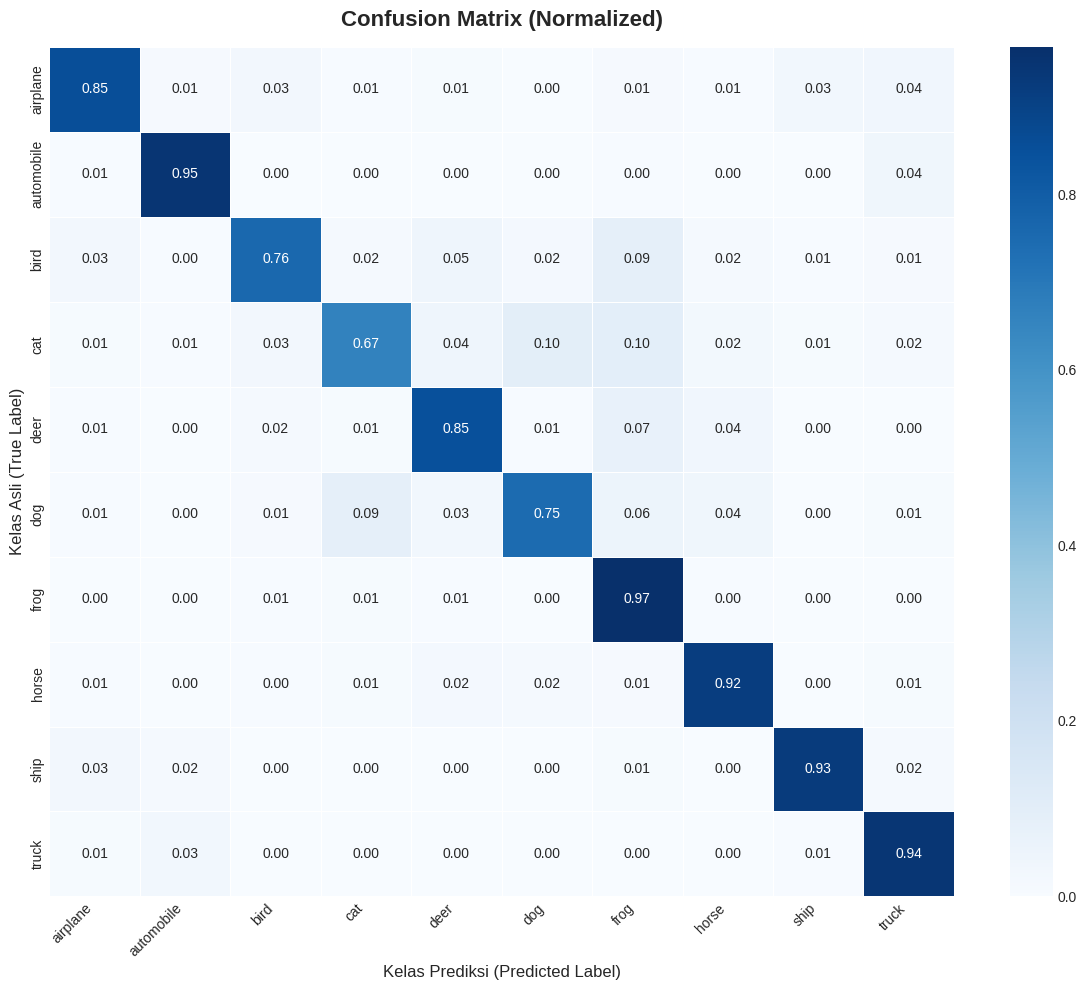

💡 Nilai di diagonal = akurasi per kelas. Semakin gelap = semakin baik.


In [ ]:
# ── Confusion Matrix ──────────────────────────────────────────────────────
# Confusion matrix adalah tabel yang menunjukkan:
# - Baris: kelas ASLI (ground truth)
# - Kolom: kelas PREDIKSI model
# - Diagonal = prediksi BENAR, selain diagonal = prediksi SALAH

cm = confusion_matrix(y_true, y_pred)  # Hitung confusion matrix

# Normalisasi: ubah hitungan absolut menjadi persentase (per baris = per kelas asli)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(12, 10))           # Ukuran canvas
sns.heatmap(
    cm_normalized,                     # Data confusion matrix yang sudah dinormalisasi
    annot=True,                        # Tampilkan angka di setiap sel
    fmt='.2f',                         # Format angka: 2 desimal
    cmap='Blues',                      # Warna: gradasi biru
    xticklabels=CLASS_NAMES,           # Label kolom (prediksi)
    yticklabels=CLASS_NAMES,           # Label baris (asli)
    linewidths=0.5                     # Garis pemisah antar sel
)
plt.title('Confusion Matrix (Normalized)', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Kelas Asli (True Label)', fontsize=12)      # Label sumbu y
plt.xlabel('Kelas Prediksi (Predicted Label)', fontsize=12)  # Label sumbu x
plt.xticks(rotation=45, ha='right')   # Putar label sumbu x
plt.tight_layout()
plt.show()
print('💡 Nilai di diagonal = akurasi per kelas. Semakin gelap = semakin baik.')

---
## Bagian 8: Prediksi Gambar Baru

/tmp/ipykernel_3143/3951623892.py:38: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3143/3951623892.py:38: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


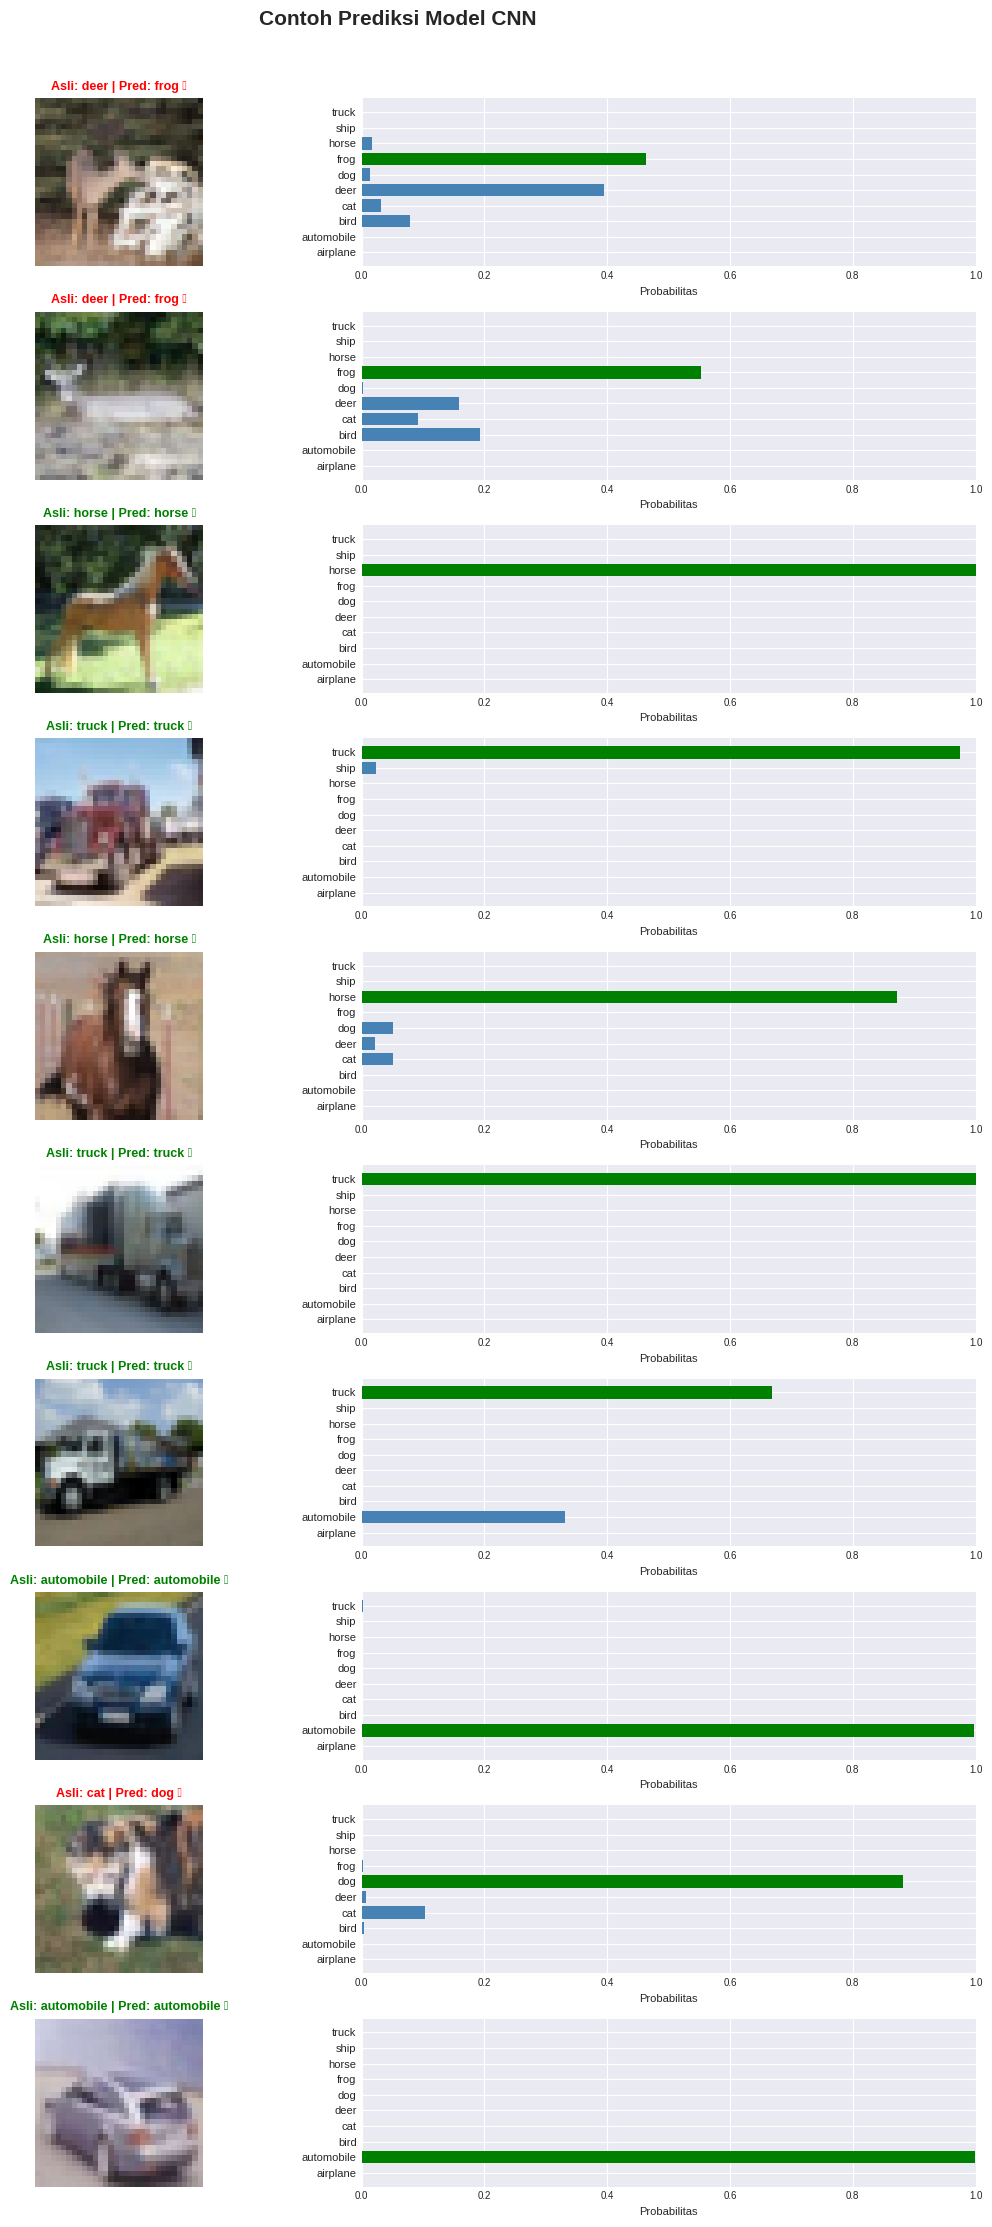

In [ ]:
# ── Visualisasi Prediksi Model ────────────────────────────────────────────
# Tampilkan contoh prediksi model pada gambar-gambar dari data test
# dengan bar probabilitas untuk setiap kelas.

NUM_DISPLAY = 10          # Jumlah gambar yang ingin ditampilkan
indices = np.random.choice(len(X_test), NUM_DISPLAY, replace=False)  # Pilih indeks acak

fig, axes = plt.subplots(NUM_DISPLAY, 2, figsize=(12, NUM_DISPLAY * 2.2))
fig.suptitle('Contoh Prediksi Model CNN', fontsize=15, fontweight='bold', y=1.01)

for row, idx in enumerate(indices):
    img     = X_test[idx]                             # Gambar asli
    true_lbl = CLASS_NAMES[y_true[idx]]               # Label kelas asli
    proba   = y_pred_proba[idx]                       # Probabilitas prediksi untuk 10 kelas
    pred_lbl = CLASS_NAMES[np.argmax(proba)]          # Kelas dengan probabilitas tertinggi
    is_correct = (true_lbl == pred_lbl)               # Apakah prediksi benar?

    # ── Kolom kiri: tampilkan gambar ──
    axes[row, 0].imshow(img)                          # Tampilkan gambar
    border_color = 'green' if is_correct else 'red'  # Bingkai hijau=benar, merah=salah
    for spine in axes[row, 0].spines.values():        # Beri warna pada bingkai (spine)
        spine.set_edgecolor(border_color)
        spine.set_linewidth(3)
    axes[row, 0].set_title(
        f'Asli: {true_lbl} | Pred: {pred_lbl} {"✓" if is_correct else "✗"}',
        color=border_color, fontsize=9, fontweight='bold'
    )
    axes[row, 0].axis('off')

    # ── Kolom kanan: bar chart probabilitas ──
    colors = ['green' if i == np.argmax(proba) else 'steelblue' for i in range(NUM_CLASSES)]
    axes[row, 1].barh(CLASS_NAMES, proba, color=colors)   # Bar horizontal tiap kelas
    axes[row, 1].set_xlim([0, 1])                         # Sumbu x: 0 sampai 1
    axes[row, 1].set_xlabel('Probabilitas', fontsize=8)
    axes[row, 1].tick_params(axis='y', labelsize=8)
    axes[row, 1].tick_params(axis='x', labelsize=7)

plt.tight_layout()
plt.show()

---
## Bagian 9: Simpan Model

In [ ]:
# ── Simpan Model ke File ──────────────────────────────────────────────────
# Setelah training selesai, simpan model agar bisa digunakan kembali
# tanpa perlu training ulang dari awal.

MODEL_PATH = 'cnn_cifar10_model.h5'    # Nama file untuk menyimpan model (format HDF5)

model.save(MODEL_PATH)                  # Simpan seluruh model: arsitektur + bobot + konfigurasi

print(f'✅ Model berhasil disimpan ke "{MODEL_PATH}"')

# ── Cara Load Model yang Sudah Disimpan ──────────────────────────────────
# Uncomment kode di bawah jika ingin memuat model yang sudah tersimpan:

# from tensorflow.keras.models import load_model
# model_loaded = load_model(MODEL_PATH)     # Muat model dari file
# print('Model berhasil dimuat kembali!')

# ── Download Model ke Komputer Lokal ─────────────────────────────────────
# Colab menyediakan cara mudah untuk mendownload file:

from google.colab import files         # Import modul file management Colab
files.download(MODEL_PATH)             # Trigger download file ke komputer lokal
print('📥 File model sedang didownload ke komputer lokal...')

✅ Model berhasil disimpan ke "cnn_cifar10_model.h5"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 File model sedang didownload ke komputer lokal...


---
## Kesimpulan

### Ringkasan Arsitektur CNN yang Dibangun:

| Blok | Lapisan | Fungsi |
|------|---------|--------|
| Blok 1 | Conv2D(32) × 2 → BN → MaxPool → Dropout(0.25) | Deteksi fitur dasar: tepi, warna |
| Blok 2 | Conv2D(64) × 2 → BN → MaxPool → Dropout(0.30) | Deteksi fitur menengah: bentuk, tekstur |
| Blok 3 | Conv2D(128) × 2 → BN → MaxPool → Dropout(0.40) | Deteksi fitur kompleks: bagian objek |
| Head  | Flatten → Dense(256) → BN → Dropout(0.50) → Dense(10, softmax) | Klasifikasi akhir |

### Teknik yang Digunakan:
- **Data Augmentation**: Memperbanyak variasi data training untuk mencegah overfitting
- **Batch Normalization**: Menstabilkan dan mempercepat training
- **Dropout**: Regularisasi untuk mencegah overfitting
- **EarlyStopping**: Otomatis berhenti saat model tidak lagi berkembang
- **ReduceLROnPlateau**: Turunkan learning rate secara adaptif
